In [2]:
import pandas as pd

for nombre in ["R1", "R2", "R3"]:
    df = pd.read_csv(nombre + ".csv")
    print(nombre, "->", len(df), "filas | columnas:", list(df.columns))
    print(df.head(3))
    print()

R1 -> 2000 filas | columnas: ['timestamp_us', 'az_crudo', 'unidad', 'fs_hz', 'pwm_pct']
   timestamp_us  az_crudo             unidad  fs_hz  pwm_pct
0           178     14808  cuentas(16384=1g)  100.0        0
1         10019     14848  cuentas(16384=1g)  100.0        0
2         20012     14876  cuentas(16384=1g)  100.0        0

R2 -> 2000 filas | columnas: ['timestamp_us', 'az_crudo', 'unidad', 'fs_hz', 'pwm_pct']
   timestamp_us  az_crudo             unidad  fs_hz  pwm_pct
0           104     14800  cuentas(16384=1g)  100.0       60
1         10018     14700  cuentas(16384=1g)  100.0       60
2         20019     14780  cuentas(16384=1g)  100.0       60

R3 -> 2000 filas | columnas: ['timestamp_us', 'az_crudo', 'unidad', 'fs_hz', 'pwm_pct']
   timestamp_us  az_crudo             unidad  fs_hz  pwm_pct
0           104     14812  cuentas(16384=1g)  100.0      100
1         10015     14608  cuentas(16384=1g)  100.0      100
2         20028     14896  cuentas(16384=1g)  100.0      100



In [3]:
import pandas as pd
import numpy as np

print("SNR DE ENTRADA")
for nombre in ["R1", "R2", "R3"]:
    df = pd.read_csv(nombre + ".csv")
    x = df["az_crudo"].values.astype(float)

    Ps = np.mean(x) ** 2
    Pn = np.mean((x - np.mean(x)) ** 2)
    snr = 10 * np.log10(Ps / Pn)

    print(nombre, "| Ps = %.0f | Pn = %.0f | SNR = %.2f dB" % (Ps, Pn, snr))

SNR DE ENTRADA
R1 | Ps = 219771315 | Pn = 7787 | SNR = 44.51 dB
R2 | Ps = 219498151 | Pn = 27386 | SNR = 39.04 dB
R3 | Ps = 218922149 | Pn = 72716 | SNR = 34.79 dB


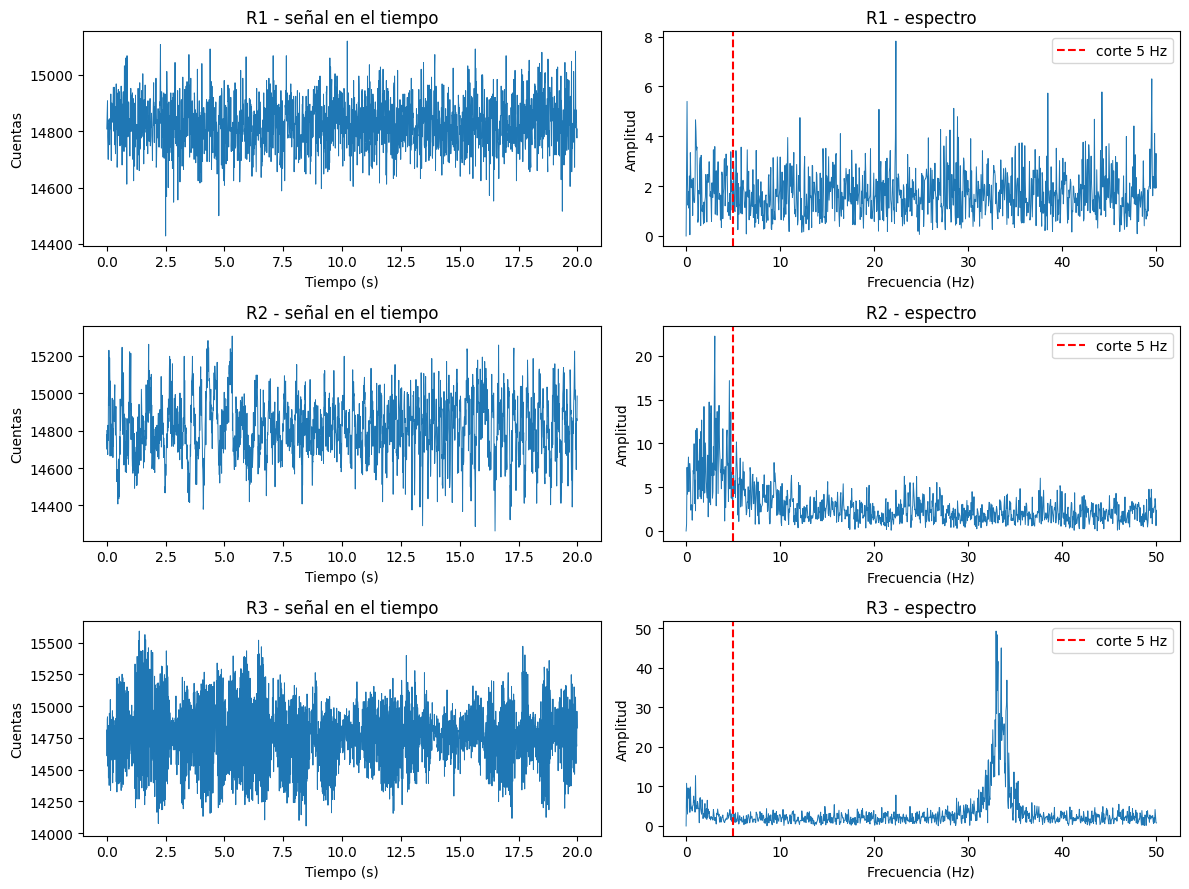

In [4]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(3, 2, figsize=(12, 9))

for k, nombre in enumerate(["R1", "R2", "R3"]):
    df = pd.read_csv(nombre + ".csv")
    x = df["az_crudo"].values.astype(float)
    fs = 100
    t = np.arange(len(x)) / fs

    # Tiempo
    ejes[k, 0].plot(t, x, linewidth=0.7)
    ejes[k, 0].set_title(nombre + " - señal en el tiempo")
    ejes[k, 0].set_xlabel("Tiempo (s)")
    ejes[k, 0].set_ylabel("Cuentas")

    # Espectro (sin la media, para ver solo el ruido)
    xc = x - np.mean(x)
    X = np.abs(np.fft.rfft(xc)) / len(xc)
    f = np.fft.rfftfreq(len(xc), 1 / fs)
    ejes[k, 1].plot(f, X, linewidth=0.7)
    ejes[k, 1].set_title(nombre + " - espectro")
    ejes[k, 1].set_xlabel("Frecuencia (Hz)")
    ejes[k, 1].set_ylabel("Amplitud")
    ejes[k, 1].axvline(5, color="r", linestyle="--", label="corte 5 Hz")
    ejes[k, 1].legend()

plt.tight_layout()
plt.show()

In [6]:
from scipy import signal

fs = 100
fc = 5

# FIR orden 20 (21 coeficientes), por ventana
b_fir = signal.firwin(21, fc, window="hamming", fs=fs)

# IIR Butterworth orden 2
b_iir, a_iir = signal.butter(2, fc, btype="low", fs=fs)

print("FIR b =", np.round(b_fir, 5))
print("Suma de coeficientes FIR =", round(b_fir.sum(), 5))
print()
print("IIR b =", np.round(b_iir, 5))
print("IIR a =", np.round(a_iir, 5))

polos = np.roots(a_iir)
print("Polos IIR =", np.round(polos, 4))
print("Tamaño de cada polo =", np.round(np.abs(polos), 4))

FIR b = [0.      0.00133 0.00465 0.01175 0.02378 0.04072 0.06116 0.0824  0.10108
 0.1139  0.11846 0.1139  0.10108 0.0824  0.06116 0.04072 0.02378 0.01175
 0.00465 0.00133 0.     ]
Suma de coeficientes FIR = 1.0

IIR b = [0.02008 0.04017 0.02008]
IIR a = [ 1.      -1.56102  0.64135]
Polos IIR = [0.7805+0.1793j 0.7805-0.1793j]
Tamaño de cada polo = [0.8008 0.8008]


In [7]:
import time

def snr_db(x):
    Ps = np.mean(x) ** 2
    Pn = np.mean((x - np.mean(x)) ** 2)
    return 10 * np.log10(Ps / Pn)

corte = 100   # primer segundo = 100 datos a 100 Hz

print("%-3s | %-8s | %-8s | %-8s | %-8s | %-8s | %-10s | %-10s" %
      ("", "SNR_in", "SNR_FIR", "dSNR_FIR", "SNR_IIR", "dSNR_IIR", "dMedia_FIR", "dMedia_IIR"))

for nombre in ["R1", "R2", "R3"]:
    df = pd.read_csv(nombre + ".csv")
    x = df["az_crudo"].values.astype(float)

    # Tiempo de ejecución (promedio de 200 repeticiones)
    t0 = time.perf_counter()
    for _ in range(200):
        y_fir = signal.lfilter(b_fir, [1.0], x)
    t_fir = (time.perf_counter() - t0) / 200 * 1e6

    t0 = time.perf_counter()
    for _ in range(200):
        y_iir = signal.lfilter(b_iir, a_iir, x)
    t_iir = (time.perf_counter() - t0) / 200 * 1e6

    # Quitar el primer segundo a entrada y salidas (mismos datos para todos)
    x_c   = x[corte:]
    yf_c  = y_fir[corte:]
    yi_c  = y_iir[corte:]

    snr_in  = snr_db(x_c)
    snr_f   = snr_db(yf_c)
    snr_i   = snr_db(yi_c)

    dm_f = np.mean(yf_c) - np.mean(x_c)
    dm_i = np.mean(yi_c) - np.mean(x_c)

    print("%-3s | %-8.2f | %-8.2f | %-8.2f | %-8.2f | %-8.2f | %-10.2f | %-10.2f" %
          (nombre, snr_in, snr_f, snr_f - snr_in, snr_i, snr_i - snr_in, dm_f, dm_i))
    print("      tiempo FIR = %.1f us | tiempo IIR = %.1f us" % (t_fir, t_iir))

    | SNR_in   | SNR_FIR  | dSNR_FIR | SNR_IIR  | dSNR_IIR | dMedia_FIR | dMedia_IIR
R1  | 44.48    | 54.34    | 9.86     | 53.46    | 8.99     | -0.07      | -0.04     
      tiempo FIR = 274.0 us | tiempo IIR = 36.1 us
R2  | 39.10    | 43.37    | 4.27     | 42.46    | 3.36     | 0.12       | 0.44      
      tiempo FIR = 486.9 us | tiempo IIR = 43.7 us
R3  | 34.76    | 47.97    | 13.21    | 47.58    | 12.82    | -0.31      | -0.15     
      tiempo FIR = 236.5 us | tiempo IIR = 36.0 us


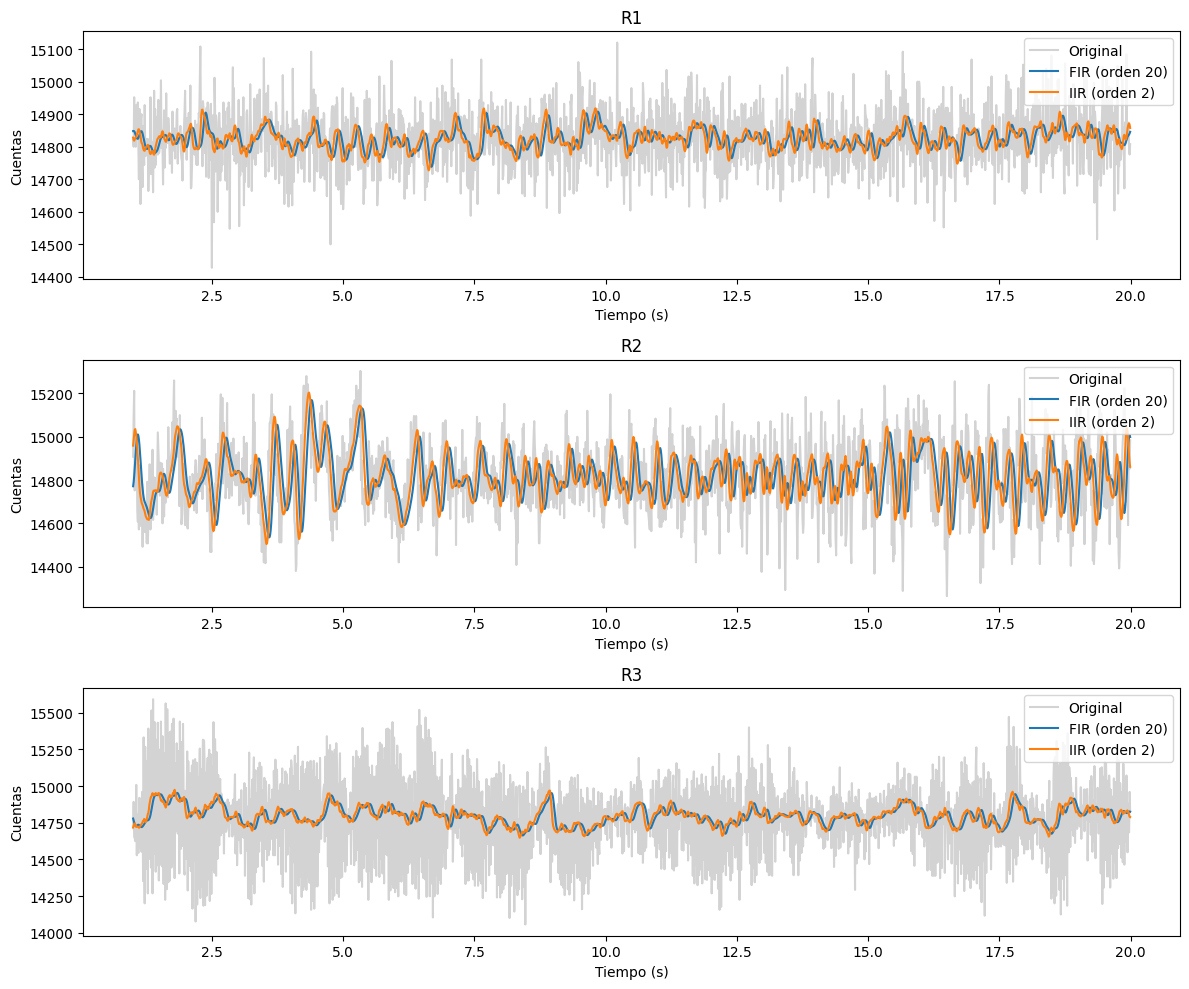

In [8]:
fig, ejes = plt.subplots(3, 1, figsize=(12, 10))

for k, nombre in enumerate(["R1", "R2", "R3"]):
    df = pd.read_csv(nombre + ".csv")
    x = df["az_crudo"].values.astype(float)
    t = np.arange(len(x)) / 100

    y_fir = signal.lfilter(b_fir, [1.0], x)
    y_iir = signal.lfilter(b_iir, a_iir, x)

    ejes[k].plot(t[100:], x[100:], color="lightgray", label="Original")
    ejes[k].plot(t[100:], y_fir[100:], label="FIR (orden 20)")
    ejes[k].plot(t[100:], y_iir[100:], label="IIR (orden 2)")
    ejes[k].set_title(nombre)
    ejes[k].set_xlabel("Tiempo (s)")
    ejes[k].set_ylabel("Cuentas")
    ejes[k].legend(loc="upper right")

plt.tight_layout()
plt.show()

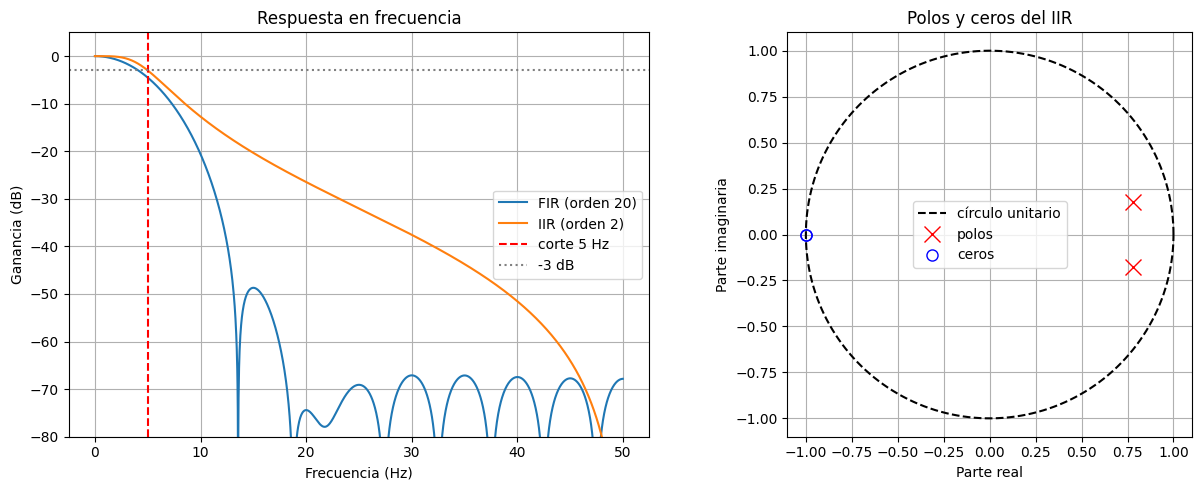

In [9]:
w, h_fir = signal.freqz(b_fir, [1.0], worN=2048, fs=100)
w, h_iir = signal.freqz(b_iir, a_iir, worN=2048, fs=100)

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

# Respuesta en frecuencia
ejes[0].plot(w, 20*np.log10(np.abs(h_fir) + 1e-12), label="FIR (orden 20)")
ejes[0].plot(w, 20*np.log10(np.abs(h_iir) + 1e-12), label="IIR (orden 2)")
ejes[0].axvline(5, color="r", linestyle="--", label="corte 5 Hz")
ejes[0].axhline(-3, color="gray", linestyle=":", label="-3 dB")
ejes[0].set_ylim(-80, 5)
ejes[0].set_xlabel("Frecuencia (Hz)")
ejes[0].set_ylabel("Ganancia (dB)")
ejes[0].set_title("Respuesta en frecuencia")
ejes[0].legend()
ejes[0].grid(True)

# Polos del IIR en el círculo unitario
ang = np.linspace(0, 2*np.pi, 400)
ejes[1].plot(np.cos(ang), np.sin(ang), "k--", label="círculo unitario")
polos = np.roots(a_iir)
ceros = np.roots(b_iir)
ejes[1].plot(polos.real, polos.imag, "rx", markersize=12, label="polos")
ejes[1].plot(ceros.real, ceros.imag, "bo", markersize=8, fillstyle="none", label="ceros")
ejes[1].set_aspect("equal")
ejes[1].set_xlabel("Parte real")
ejes[1].set_ylabel("Parte imaginaria")
ejes[1].set_title("Polos y ceros del IIR")
ejes[1].legend()
ejes[1].grid(True)

plt.tight_layout()
plt.show()

In [10]:
print("RETARDO OBSERVADO (en muestras y en segundos)")

for nombre in ["R1", "R2", "R3"]:
    df = pd.read_csv(nombre + ".csv")
    x = df["az_crudo"].values.astype(float)
    x = x - np.mean(x)          # quitamos la media solo para comparar la forma

    y_fir = signal.lfilter(b_fir, [1.0], x)
    y_iir = signal.lfilter(b_iir, a_iir, x)

    # Retardo respecto a una referencia suave (la misma entrada pasada por un filtro sin retardo)
    ref = signal.filtfilt(b_iir, a_iir, x)   # filtrado ida y vuelta: sin retardo

    def retardo(y):
        y = y[100:] - np.mean(y[100:])
        r = ref[100:] - np.mean(ref[100:])
        corr = np.correlate(y, r, mode="full")
        lags = np.arange(-len(r) + 1, len(r))
        return -lags[np.argmax(corr)]

    d_f = retardo(y_fir)
    d_i = retardo(y_iir)
    print("%s | FIR: %d muestras = %.2f s | IIR: %d muestras = %.2f s" %
          (nombre, d_f, d_f / 100, d_i, d_i / 100))

print()
print("Teorico FIR = 10 muestras = 0.10 s")

RETARDO OBSERVADO (en muestras y en segundos)
R1 | FIR: -10 muestras = -0.10 s | IIR: -5 muestras = -0.05 s
R2 | FIR: -10 muestras = -0.10 s | IIR: -5 muestras = -0.05 s
R3 | FIR: -10 muestras = -0.10 s | IIR: -5 muestras = -0.05 s

Teorico FIR = 10 muestras = 0.10 s


In [11]:
def snr_db(x):
    Ps = np.mean(x) ** 2
    Pn = np.mean((x - np.mean(x)) ** 2)
    return 10 * np.log10(Ps / Pn)

filas = []
for nombre in ["R1", "R2", "R3"]:
    x = pd.read_csv(nombre + ".csv")["az_crudo"].values.astype(float)

    t0 = time.perf_counter()
    for _ in range(200):
        y_fir = signal.lfilter(b_fir, [1.0], x)
    t_fir = (time.perf_counter() - t0) / 200 * 1e6

    t0 = time.perf_counter()
    for _ in range(200):
        y_iir = signal.lfilter(b_iir, a_iir, x)
    t_iir = (time.perf_counter() - t0) / 200 * 1e6

    xc, yf, yi = x[100:], y_fir[100:], y_iir[100:]
    s_in, s_f, s_i = snr_db(xc), snr_db(yf), snr_db(yi)

    filas.append({"Registro": nombre,
                  "SNR_entrada_dB": round(s_in, 2),
                  "SNR_FIR_dB": round(s_f, 2), "dSNR_FIR_dB": round(s_f - s_in, 2),
                  "SNR_IIR_dB": round(s_i, 2), "dSNR_IIR_dB": round(s_i - s_in, 2),
                  "cambio_media_FIR": round(np.mean(yf) - np.mean(xc), 2),
                  "cambio_media_IIR": round(np.mean(yi) - np.mean(xc), 2),
                  "tiempo_FIR_us": round(t_fir, 1), "tiempo_IIR_us": round(t_iir, 1)})

tabla = pd.DataFrame(filas)
tabla["orden_FIR"] = 20
tabla["orden_IIR"] = 2
tabla["retardo_FIR_muestras"] = 10
tabla["retardo_IIR_muestras"] = 5
tabla["estabilidad_FIR"] = "estable (sin realimentación)"
tabla["estabilidad_IIR"] = "estable (polos 0.80 < 1)"

tabla.to_csv("tabla_resultados.csv", index=False)
print(tabla.T)

                                                 0  \
Registro                                        R1   
SNR_entrada_dB                               44.48   
SNR_FIR_dB                                   54.34   
dSNR_FIR_dB                                   9.86   
SNR_IIR_dB                                   53.46   
dSNR_IIR_dB                                   8.99   
cambio_media_FIR                             -0.07   
cambio_media_IIR                             -0.04   
tiempo_FIR_us                                421.0   
tiempo_IIR_us                                 81.9   
orden_FIR                                       20   
orden_IIR                                        2   
retardo_FIR_muestras                            10   
retardo_IIR_muestras                             5   
estabilidad_FIR       estable (sin realimentación)   
estabilidad_IIR           estable (polos 0.80 < 1)   

                                                 1  \
Registro                   

fs = 100.0 Hz | corte = 5 Hz
FIR b: [0.      0.00133 0.00465 0.01175 0.02378 0.04072 0.06116 0.0824  0.10108
 0.1139  0.11846 0.1139  0.10108 0.0824  0.06116 0.04072 0.02378 0.01175
 0.00465 0.00133 0.     ]
IIR b: [0.02008 0.04017 0.02008] | a: [ 1.      -1.56102  0.64135]
Polos IIR: [0.7805+0.1793j 0.7805-0.1793j] | modulos: [0.8008 0.8008]
Ecuacion IIR: y[n] = 0.02008 x[n] + 0.04017 x[n-1] + 0.02008 x[n-2] + 1.56102 y[n-1] - 0.64135 y[n-2]
Ecuacion FIR: y[n] = suma_{k=0..20} h[k] x[n-k]  (h simetrico)

                                                 0  \
Registro                                        R1   
Ps                                       219750352   
Pn                                          7841.5   
SNR_entrada_dB                               44.48   
SNR_FIR_dB                                   54.34   
dSNR_FIR_dB                                   9.86   
SNR_IIR_dB                                   53.46   
dSNR_IIR_dB                                   8.99   
cam

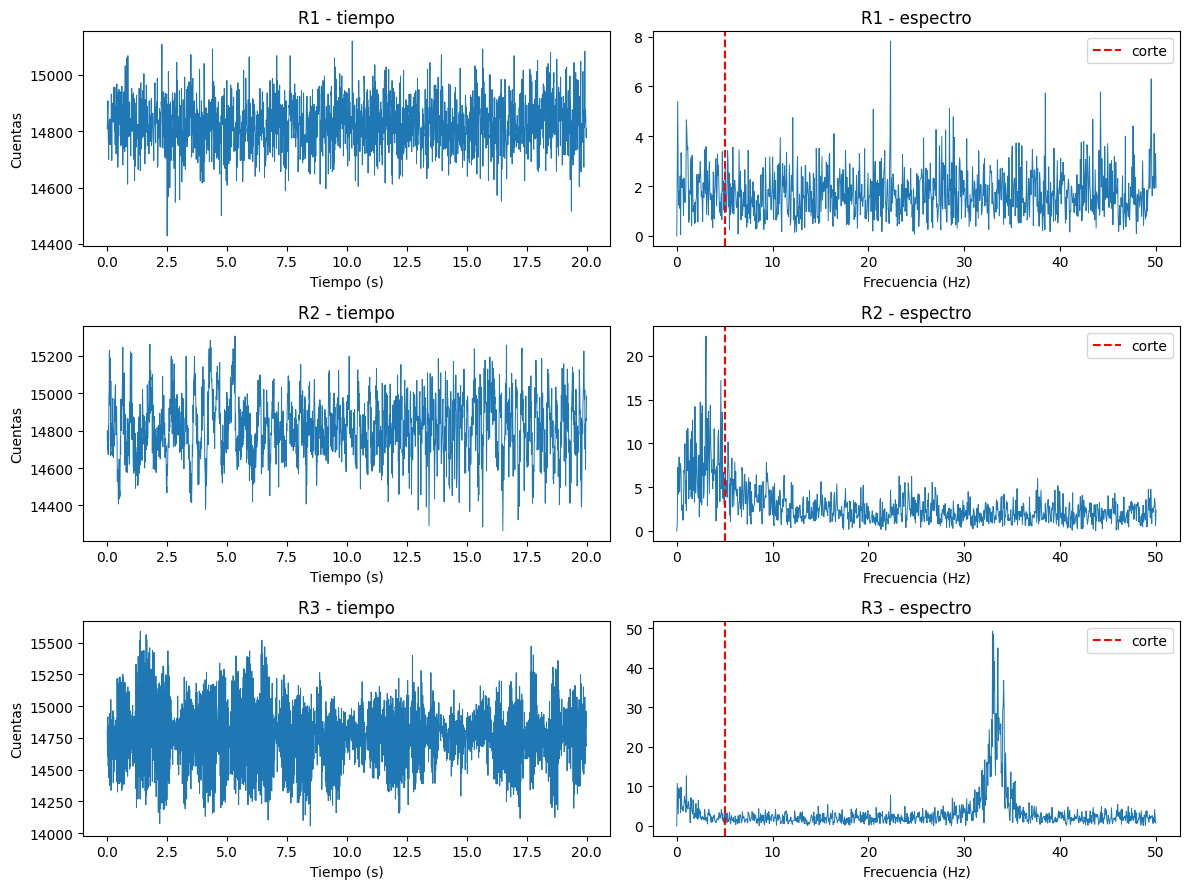

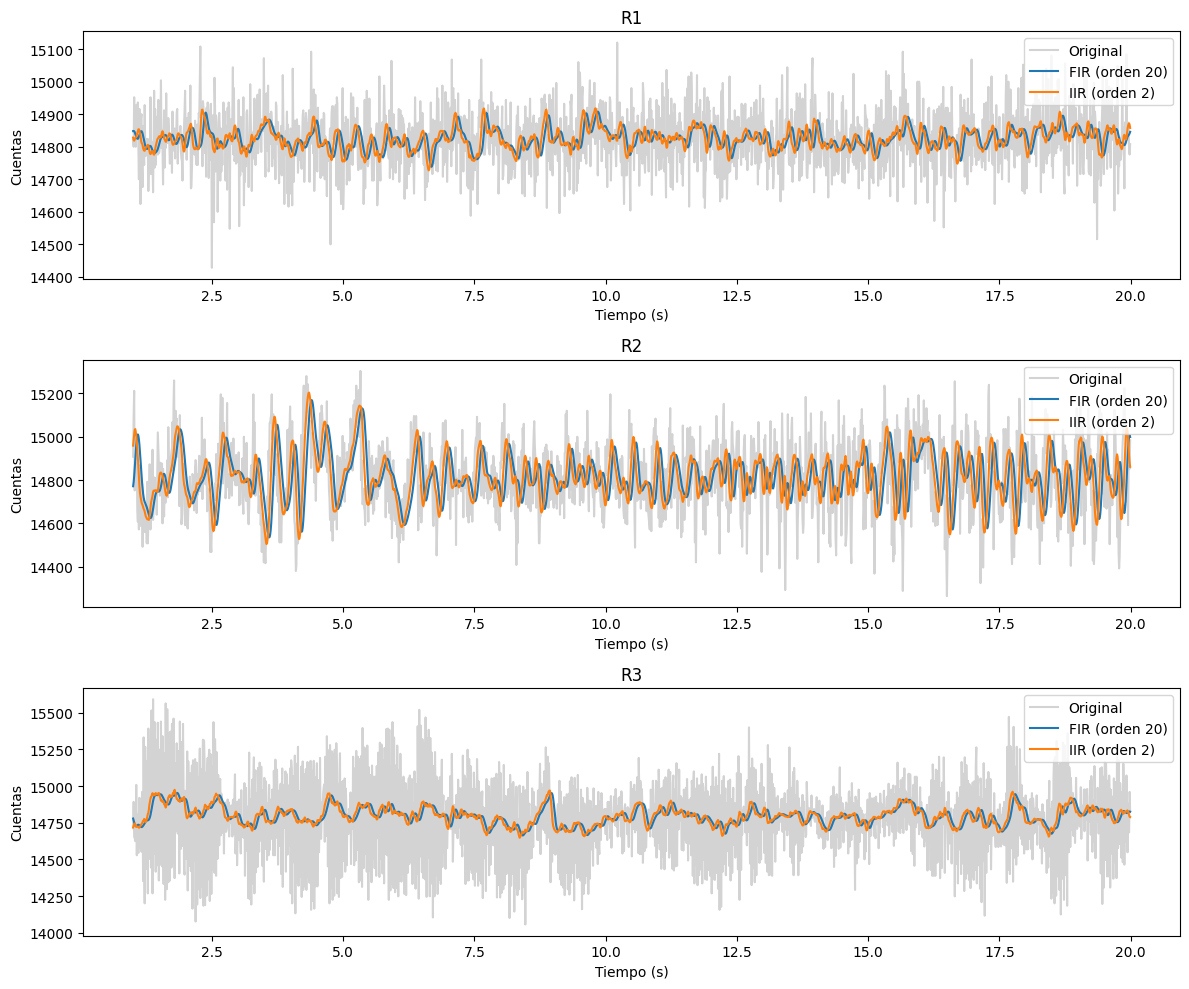

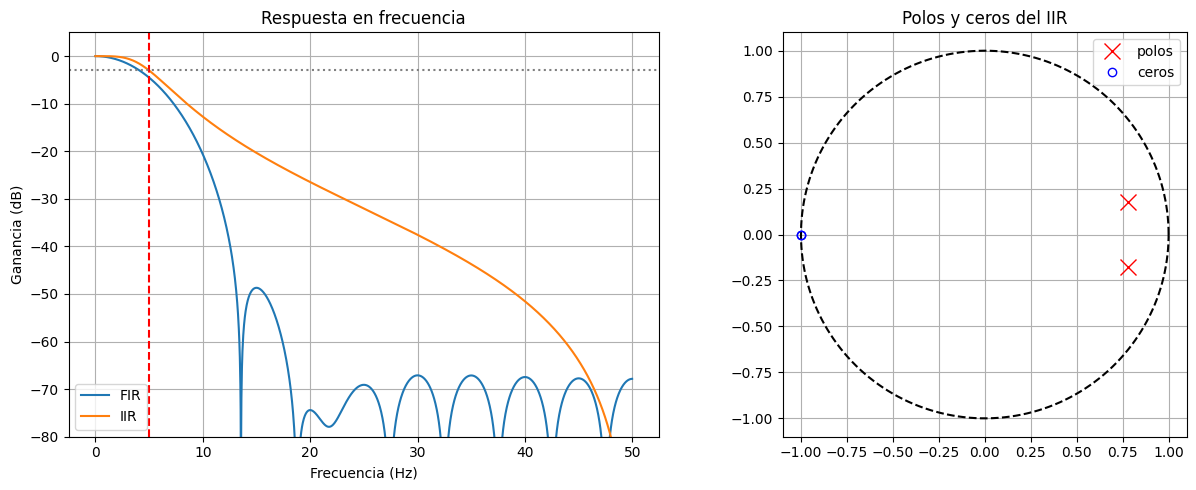

In [12]:
import numpy as np, pandas as pd, time
import matplotlib.pyplot as plt
from scipy import signal

# ---------- PARÁMETROS ----------
REGISTROS = ["R1", "R2", "R3"]
FC = 5            # frecuencia de corte (Hz), igual para FIR e IIR
ORDEN_FIR = 20
ORDEN_IIR = 2
DESCARTE_S = 1    # se elimina el primer segundo de las salidas
# --------------------------------

def snr_db(x):
    Ps = np.mean(x) ** 2
    Pn = np.mean((x - np.mean(x)) ** 2)
    return 10 * np.log10(Ps / Pn), Ps, Pn

def retardo_obs(y, ref, d):
    y = y[d:] - np.mean(y[d:])
    r = ref[d:] - np.mean(ref[d:])
    c = np.correlate(y, r, mode="full")
    return int(np.arange(-len(r) + 1, len(r))[np.argmax(c)])

# Filtros
fs = float(pd.read_csv("R1.csv")["fs_hz"].iloc[0])
d = int(DESCARTE_S * fs)
b_fir = signal.firwin(ORDEN_FIR + 1, FC, window="hamming", fs=fs)
b_iir, a_iir = signal.butter(ORDEN_IIR, FC, btype="low", fs=fs)
polos = np.roots(a_iir)

print("fs =", fs, "Hz | corte =", FC, "Hz")
print("FIR b:", np.round(b_fir, 5))
print("IIR b:", np.round(b_iir, 5), "| a:", np.round(a_iir, 5))
print("Polos IIR:", np.round(polos, 4), "| modulos:", np.round(np.abs(polos), 4))
print("Ecuacion IIR: y[n] = %.5f x[n] + %.5f x[n-1] + %.5f x[n-2] + %.5f y[n-1] - %.5f y[n-2]"
      % (b_iir[0], b_iir[1], b_iir[2], -a_iir[1], a_iir[2]))
print("Ecuacion FIR: y[n] = suma_{k=0..20} h[k] x[n-k]  (h simetrico)\n")

filas, datos = [], {}
for nom in REGISTROS:
    x = pd.read_csv(nom + ".csv")["az_crudo"].values.astype(float)

    tf = []
    for _ in range(200):
        t0 = time.perf_counter(); yf = signal.lfilter(b_fir, [1.0], x); tf.append(time.perf_counter() - t0)
    ti = []
    for _ in range(200):
        t0 = time.perf_counter(); yi = signal.lfilter(b_iir, a_iir, x); ti.append(time.perf_counter() - t0)

    ref = signal.filtfilt(b_iir, a_iir, x - np.mean(x))
    df_ = retardo_obs(yf - np.mean(x), ref, d)
    di_ = retardo_obs(yi - np.mean(x), ref, d)

    xc, yfc, yic = x[d:], yf[d:], yi[d:]
    s_in, Ps, Pn = snr_db(xc)
    s_f = snr_db(yfc)[0]
    s_i = snr_db(yic)[0]

    filas.append({"Registro": nom, "Ps": round(Ps), "Pn": round(Pn, 1),
                  "SNR_entrada_dB": round(s_in, 2),
                  "SNR_FIR_dB": round(s_f, 2), "dSNR_FIR_dB": round(s_f - s_in, 2),
                  "SNR_IIR_dB": round(s_i, 2), "dSNR_IIR_dB": round(s_i - s_in, 2),
                  "cambio_media_FIR": round(np.mean(yfc) - np.mean(xc), 2),
                  "cambio_media_IIR": round(np.mean(yic) - np.mean(xc), 2),
                  "orden_FIR": ORDEN_FIR, "orden_IIR": ORDEN_IIR,
                  "retardo_FIR_muestras": df_, "retardo_IIR_muestras": di_,
                  "tiempo_FIR_us": round(np.median(tf) * 1e6, 1),
                  "tiempo_IIR_us": round(np.median(ti) * 1e6, 1),
                  "estab_FIR": "estable (sin realimentacion)",
                  "estab_IIR": "estable (polos %.2f < 1)" % np.abs(polos).max()})
    datos[nom] = (x, yf, yi)

tabla = pd.DataFrame(filas)
tabla.to_csv("tabla_resultados.csv", index=False)
print(tabla.T)

# ---------- GRÁFICAS (se guardan como PNG) ----------
# 1. Tiempo y espectro de la señal cruda
fig, ax = plt.subplots(3, 2, figsize=(12, 9))
for k, nom in enumerate(REGISTROS):
    x = datos[nom][0]; t = np.arange(len(x)) / fs
    ax[k, 0].plot(t, x, lw=0.7); ax[k, 0].set_title(nom + " - tiempo")
    ax[k, 0].set_xlabel("Tiempo (s)"); ax[k, 0].set_ylabel("Cuentas")
    xc = x - np.mean(x)
    ax[k, 1].plot(np.fft.rfftfreq(len(xc), 1/fs), np.abs(np.fft.rfft(xc)) / len(xc), lw=0.7)
    ax[k, 1].axvline(FC, color="r", ls="--", label="corte")
    ax[k, 1].set_title(nom + " - espectro"); ax[k, 1].set_xlabel("Frecuencia (Hz)"); ax[k, 1].legend()
plt.tight_layout(); plt.savefig("fig1_senales_espectro.png", dpi=150); plt.show()

# 2. Original vs filtradas
fig, ax = plt.subplots(3, 1, figsize=(12, 10))
for k, nom in enumerate(REGISTROS):
    x, yf, yi = datos[nom]; t = np.arange(len(x)) / fs
    ax[k].plot(t[d:], x[d:], color="lightgray", label="Original")
    ax[k].plot(t[d:], yf[d:], label="FIR (orden 20)")
    ax[k].plot(t[d:], yi[d:], label="IIR (orden 2)")
    ax[k].set_title(nom); ax[k].set_xlabel("Tiempo (s)"); ax[k].set_ylabel("Cuentas"); ax[k].legend(loc="upper right")
plt.tight_layout(); plt.savefig("fig2_filtradas.png", dpi=150); plt.show()

# 3. Respuesta en frecuencia y polos
w, hf = signal.freqz(b_fir, [1.0], worN=2048, fs=fs)
w, hi = signal.freqz(b_iir, a_iir, worN=2048, fs=fs)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(w, 20*np.log10(np.abs(hf) + 1e-12), label="FIR")
ax[0].plot(w, 20*np.log10(np.abs(hi) + 1e-12), label="IIR")
ax[0].axvline(FC, color="r", ls="--"); ax[0].axhline(-3, color="gray", ls=":")
ax[0].set_ylim(-80, 5); ax[0].set_xlabel("Frecuencia (Hz)"); ax[0].set_ylabel("Ganancia (dB)")
ax[0].set_title("Respuesta en frecuencia"); ax[0].legend(); ax[0].grid(True)
ang = np.linspace(0, 2*np.pi, 400)
ax[1].plot(np.cos(ang), np.sin(ang), "k--")
ax[1].plot(polos.real, polos.imag, "rx", ms=12, label="polos")
ceros = np.roots(b_iir)
ax[1].plot(ceros.real, ceros.imag, "bo", fillstyle="none", label="ceros")
ax[1].set_aspect("equal"); ax[1].set_title("Polos y ceros del IIR"); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.savefig("fig3_respuesta_polos.png", dpi=150); plt.show()